In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

In [2]:
file_url = "https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv"
df = pd.read_csv(file_url)
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [3]:
categorical_columns = ["lead_source", "industry", "employment_status", "location"]
numerical_columns = ["annual_income", "number_of_courses_viewed", "interaction_count", "lead_score"]

### EDA

In [4]:
for col in categorical_columns:
    print(f"{col}")
    print("\tNumber of Unique Values:", df[col].nunique())
    print("\tNumber of Null Values:", df[col].isnull().sum())
    print()
    # Replacing the nulls with 'NA'
    df[col] = df[col].fillna('NA')

for col in numerical_columns:
    print(f"{col}")
    print("\tNumber of Null Values:", df[col].isnull().sum())
    print()
    df[col] = df[col].fillna(0.0)

lead_source
	Number of Unique Values: 5
	Number of Null Values: 148

industry
	Number of Unique Values: 6
	Number of Null Values: 240

employment_status
	Number of Unique Values: 4
	Number of Null Values: 194

location
	Number of Unique Values: 5
	Number of Null Values: 208

annual_income
	Number of Null Values: 369

number_of_courses_viewed
	Number of Null Values: 0

interaction_count
	Number of Null Values: 0

lead_score
	Number of Null Values: 35



### Q1

In [5]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

del df_train['converted']
del df_val['converted']
del df_test['converted']

In [6]:
from sklearn.metrics import roc_auc_score

for col in numerical_columns:
    auc = roc_auc_score(y_train, df_train[col])

    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])

    print(col, auc)

annual_income 0.6081977776250831
number_of_courses_viewed 0.7229894623989618
interaction_count 0.7649203047563227
lead_score 0.7882254810906102


### Q2

In [7]:
dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(df_train[categorical_columns + numerical_columns].to_dict(orient="records"))
X_val = dv.transform(df_val[categorical_columns + numerical_columns].to_dict(orient="records"))

model = LogisticRegression(solver="liblinear", C=1.0, max_iter=1000)
model.fit(X_train, y_train)
y_score = model.predict_proba(X_val)[:, 1]

print(round(roc_auc_score(y_val, y_score), 3))

0.732


### Q3 , Q4

In [8]:
from sklearn.metrics import precision_score, recall_score

thresholds = np.arange(0, 1.01, 0.01)
scores = []

for t in thresholds:
    y_pred = (y_score >= t)
    precision = precision_score(y_val, y_pred, zero_division=0)
    recall = recall_score(y_val, y_pred, zero_division=0)
    
    if precision == 0 and recall == 0:
        continue
    
    diff = abs(precision - recall)
    if precision + recall != 0:
        f1 = 2 * ((precision * recall)/(precision + recall))
    else:
        f1 = 0
    scores.append((t, precision, recall, diff, f1))

columns = ['threshold', 'precision', 'recall', 'diff', 'f1']
df_scores = pd.DataFrame(scores, columns=columns)


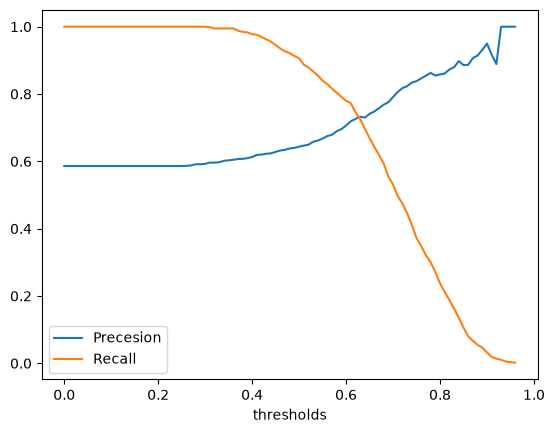

In [9]:
plt.plot(df_scores.threshold, df_scores.precision, label='Precesion')
plt.plot(df_scores.threshold, df_scores.recall, label='Recall')
plt.xlabel("thresholds")
plt.legend()

In [10]:
interesection_row= df_scores.loc[df_scores["diff"].idxmin()]
interesection_row


threshold    0.630000
precision    0.732759
recall       0.725256
diff         0.007503
f1           0.728988
Name: 63, dtype: float64

In [11]:
best_threshold_row = df_scores.loc[df_scores["f1"].idxmax()]
best_threshold_row

threshold    0.410000
precision    0.619048
recall       0.976109
diff         0.357062
f1           0.757616
Name: 41, dtype: float64

### Q5

In [22]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical_columns + numerical_columns].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver="liblinear", C=C, max_iter=1000)
    model.fit(X_train, y_train)
    
    return dv, model

In [23]:
def predict(df, dv, model):
    dicts = df[categorical_columns + numerical_columns].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [24]:
from sklearn.model_selection import KFold

n_splits = 5

kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train.converted.values
    y_val = df_val.converted.values

    dv, model = train(df_train, y_train)
    y_pred = predict(df_val, dv, model)

    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)

print('Std Deviation =  %.3f' % (np.std(scores)))

Std Deviation =  0.007


### Q6

In [21]:
import warnings
from sklearn.exceptions import ConvergenceWarning
from sklearn.model_selection import KFold

warnings.filterwarnings("ignore", category=ConvergenceWarning)

n_splits = 5

for C in [0.000001, 0.001, 1]:
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)
    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        dv, model = train(df_train, y_train, C)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print('C=%s, Std Deviation =  %.3f, Mean = %.3f' % (C, np.std(scores),np.mean(scores)))

C=1e-06, Std Deviation =  0.019, Mean = 0.615
C=0.001, Std Deviation =  0.013, Mean = 0.783
C=1, Std Deviation =  0.013, Mean = 0.790
